# Certified equilibrium: the basics

`discopt-calphad` computes a CALPHAD phase equilibrium in two steps:

1. a **restricted solve** minimizes G over the composition sets found so far.
   Its element-balance multipliers are the chemical potentials μ;
2. **pricing** minimizes the tangent-plane distance Ψ(y) = G(y) − μ·A(y) of
   every phase. A negative value means a new composition set is needed (that is
   how a miscibility gap is found). A *global* lower bound Ψ ≥ −ε for every
   phase, from discopt's branch and bound, certifies the result: no state with a
   lower G exists, to within ε·RT per formula unit.

The result carries a certificate whose level says what was proved. This
notebook checks the method against two references:

- the analytic binodal of a symmetric regular solution, from textbook
  thermodynamics (M. Hillert, *Phase Equilibria, Phase Diagrams and Phase
  Transformations*, 2nd ed., Cambridge University Press, 2008, ch. 9);
- the Al–Zn assessment of S. an Mey, Z. Metallkd. 84 (1993) 451–455. Its
  invariant temperatures are compared with the evaluated experimental diagram of
  J. L. Murray, Bull. Alloy Phase Diagrams 4 (1983) 55–73.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import brentq

from discopt.calphad import CertificateLevel, RegularSolution, databases, equilibrium
from discopt.calphad.plot import plot_gx

## A regular solution with a miscibility gap

G/RT = x ln x + (1 − x) ln(1 − x) + ω x(1 − x). For ω > 2 the solution splits
in two. The binodal is symmetric, and its compositions solve
ln(x / (1 − x)) = ω (2x − 1).

In [2]:
omega = 3.0
res = equilibrium(RegularSolution("LIQ", omega=omega), x=0.5, eps=1e-5)
print(res.summary())

CERTIFIED_TO_TOLERANCE after 2 iteration(s); eps = 1e-05 RT
  mu/RT = [-0.05834135 -0.05834135]   G/RT = -0.0583413494
  LIQ: x = [0.07072019 0.92927981]  amount = 0.50000000
  LIQ: x = [0.92927981 0.07072019]  amount = 0.50000000
  pricing LIQ: LB = -7.006e-06  UB = 3.509e-09
  G_R - G_global <= 7.010e-06 RT (residual 3.5e-09)


In [3]:
x_analytic = brentq(lambda x: np.log(x / (1 - x)) - omega * (2 * x - 1), 1e-9, 0.499)
x_found = sorted(float(cs.x[0]) for cs in res.composition_sets)
print(f"analytic binodal: {x_analytic:.8f} and {1 - x_analytic:.8f}")
print(f"certified sets:   {x_found[0]:.8f} and {x_found[1]:.8f}")
print("certificate:", res.certificate.level.name)

analytic binodal: 0.07072018 and 0.92927982
certified sets:   0.07072019 and 0.92927981
certificate: CERTIFIED_TO_TOLERANCE


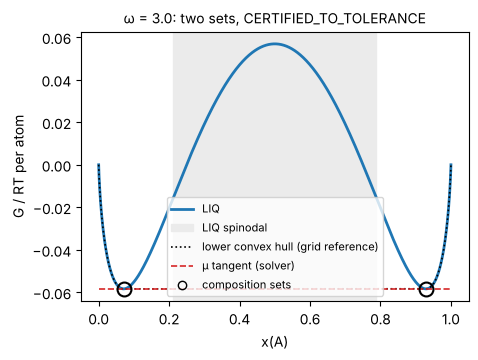

In [4]:
fig, ax = plt.subplots(figsize=(5, 3.5))
plot_gx(RegularSolution("LIQ", omega=omega), res, ax=ax)
ax.set_title(f"ω = {omega}: two sets, {res.certificate.level.name}", fontsize=10)
plt.show()

The certificate levels, from weakest to strongest:

In [5]:
for level in CertificateLevel:
    print(f"{level.value}  {level.name}")

0  FAILED
1  LOCAL_EQUILIBRIUM
2  STABILITY_SEARCHED
3  GLOBAL_SEARCH_INCOMPLETE
4  CERTIFIED_TO_TOLERANCE
5  GLOBALLY_CERTIFIED


## Al–Zn from a published TDB file

`databases.load` fetches a registered TDB file (pinned by hash) and reads it
into a symbolic `ThermoDatabase`. `applicability` reports which phases can be
modeled in a system, and why not for the others.

In [6]:
db = databases.load("alzn_mey")
print(db.applicability(("AL", "ZN")))
phases = list(db.phase_models(("AL", "ZN")).values())

{'LIQUID': 'ok', 'FCC_A1': 'ok', 'HCP_A3': 'ok'}


A certified equilibrium inside the FCC miscibility gap, at 580 K:

In [7]:
res = equilibrium(phases, x=0.6, T=580.0)
print(res.summary())

CERTIFIED_TO_TOLERANCE after 2 iteration(s); T = 580 K; eps = 1e-05 RT
  mu/RT = [-4.06395176 -5.6391128 ]   G/RT = -4.6940161749
  FCC_A1: x = [0.46153765 0.53846235]  amount = 0.61212172
  FCC_A1: x = [0.81851136 0.18148864]  amount = 0.38787828
  pricing LIQUID: LB = 2.461e-02  UB = 2.099e-01
  pricing FCC_A1: LB = -8.608e-06  UB = 1.824e-09
  pricing HCP_A3: LB = 2.829e-03  UB = 4.666e-02
  G_R - G_global <= 8.611e-06 RT (residual 2.6e-09)


## Invariant temperatures against the experimental diagram

Each invariant is found by bisection on the assemblage, with local pricing
(`certify="none"`), which is fast:

- **eutectic** L → (Al) + (Zn): the T where liquid first appears at x(Al) = 0.2;
- **monotectoid** (Al)′ → (Al) + (Zn): the T where HCP (Zn) disappears at
  x(Al) = 0.406, the monotectoid composition;
- **critical point** of the (Al) miscibility gap: the highest T with two FCC
  sets at x(Al) = 0.605.

In [8]:
def names(x, T):
    r = equilibrium(phases, x=x, T=T, certify="none")
    return [cs.phase.name for cs in r.composition_sets if cs.amount > 1e-9]


def bisect(test, lo, hi, tol=0.02):
    """The T in [lo, hi] where test(T) turns True going down."""
    while hi - lo > tol:
        mid = 0.5 * (lo + hi)
        lo, hi = (lo, mid) if test(mid) else (mid, hi)
    return 0.5 * (lo + hi)


t_eut = bisect(lambda T: "LIQUID" in names(0.2, T), 600.0, 700.0)
t_mono = bisect(lambda T: "HCP_A3" not in names(0.406, T), 500.0, 600.0)
t_crit = bisect(lambda T: names(0.605, T).count("FCC_A1") < 2, 580.0, 680.0)

murray = {"eutectic": 381.0 + 273.15, "monotectoid": 277.0 + 273.15, "critical point": 351.5 + 273.15}
ours = {"eutectic": t_eut, "monotectoid": t_mono, "critical point": t_crit}
print(f"{'invariant':16s} {'this model':>11s} {'Murray 1983':>12s} {'difference':>11s}")
for k in murray:
    print(f"{k:16s} {ours[k]:9.1f} K {murray[k]:10.1f} K {ours[k] - murray[k]:+9.1f} K")

invariant         this model  Murray 1983  difference
eutectic             654.0 K      654.1 K      -0.2 K
monotectoid          552.7 K      550.1 K      +2.6 K
critical point       622.8 K      624.6 K      -1.8 K


The assessment reproduces the experimental invariants to within a few kelvin.
The solver only finds the model's equilibrium; how close that is to experiment
is a property of the assessment.